# Actividad Individual 4 — Validación Cruzada y Bootstrapping

**Modelo:** Regresión Logística Binaria
**Base de datos:** Retention_Tec

**Contexto del problema**
El propósito es evaluar la robustez y capacidad de generalización de un modelo que anticipa qué estudiantes tienen mayor riesgo de abandonar, para activar estrategias de retención (tutorías, becas, seguimiento). Sobre el modelo de regresión logística que ya trabajé en la actividad anterior, aplico dos técnicas de remuestreo —validación cruzada y bootstrapping— para estimar su desempeño medio y su variabilidad, y así reducir el sesgo y la varianza en la estimación del rendimiento.

Recuerdo los costos de error que definen el problema:

**Falso Positivo** (intervenir a un estudiante que no iba a abandonar) = **\$10,000**

**Falso Negativo** (no intervenir a un estudiante que sí abandona) = **\$80,000**

## Paso 0 — Importar librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    roc_curve, roc_auc_score, precision_recall_curve,
    average_precision_score, precision_score, recall_score, f1_score,
    brier_score_loss
)

## Paso 1 — Cargar los datos

In [2]:
data = pd.read_csv("Retention_Tec_versión clase_v2.csv")
data.head()

,Abandono,Gender,Age,High_School_GPA,Language_Level,Toefl
0,0,1,26,87.00,8,637
1,1,1,24,75.12,7,590
2,1,1,24,84.57,7,593
3,1,0,23,88.83,8,617
4,1,1,23,85.14,8,613


In [3]:
print("Dimensiones del dataset:", data.shape)

Dimensiones del dataset: (6620, 6)


## Paso 2 — Análisis exploratorio de datos (EDA)

Antes de modelar reviso qué tenemos: tipos de variables, distribuciones, valores faltantes, duplicados y cómo se relaciona cada variable con el abandono.

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 6620 entries, 0 to 6619
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Abandono         6620 non-null   int64  
 1   Gender           6620 non-null   int64  
 2   Age              6620 non-null   int64  
 3   High_School_GPA  6620 non-null   float64
 4   Language_Level   6620 non-null   int64  
 5   Toefl            6620 non-null   int64  
dtypes: float64(1), int64(5)
memory usage: 310.4 KB


In [5]:
data.describe()

,Abandono,Gender,Age,High_School_GPA,Language_Level,Toefl
count,6620.000000,6620.000000,6620.000000,6620.000000,6620.000000,6620.000000
mean,0.043505,0.535650,18.242145,86.630085,7.100000,585.959819
std,0.204005,0.498765,0.665880,5.780654,0.986064,42.906271
min,0.000000,0.000000,16.000000,59.133000,1.000000,398.000000
25%,0.000000,0.000000,18.000000,82.239500,7.000000,557.000000
50%,0.000000,1.000000,18.000000,86.870000,7.000000,587.000000
75%,0.000000,1.000000,19.000000,91.035500,8.000000,617.000000
max,1.000000,1.000000,26.000000,99.610000,8.000000,677.000000


### 2.1 Valores faltantes y duplicados

In [6]:
print("Valores nulos por columna:")
print(data.isna().sum())
print()
print("Registros duplicados:", data.duplicated().sum())

Valores nulos por columna:
Abandono           0
Gender             0
Age                0
High_School_GPA    0
Language_Level     0
Toefl              0
dtype: int64

Registros duplicados: 51


> No hay valores nulos. Hay **51 registros duplicados**, pero en esta ocasión **los conservo**: no tengo un identificador de estudiante que me permita afirmar que son errores de captura, así que bien pueden ser estudiantes distintos con las mismas características. Eliminarlos supondría descartar información real, por lo que trabajo con los **6,620 registros** completos.

### 2.2 Balance de clases — variable objetivo Abandono

In [7]:
print(data['Abandono'].value_counts())
print()
print(data['Abandono'].value_counts(normalize=True).round(3))

Abandono
0    6332
1     288
Name: count, dtype: int64

Abandono
0    0.956
1    0.044
Name: proportion, dtype: float64


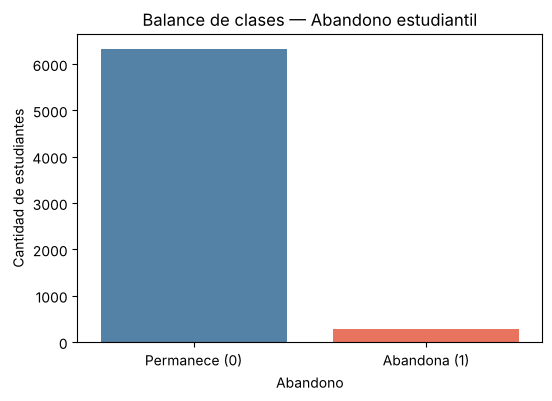

Tasa de abandono: 4.4%


In [8]:
plt.figure(figsize=(6, 4))
plt.title("Balance de clases — Abandono estudiantil")
sns.countplot(x='Abandono', data=data, hue='Abandono', palette=['steelblue', 'tomato'], legend=False)
plt.xticks([0, 1], ['Permanece (0)', 'Abandona (1)'])
plt.xlabel("Abandono")
plt.ylabel("Cantidad de estudiantes")
plt.show()

print(f"Tasa de abandono: {data['Abandono'].mean()*100:.1f}%")

> Solo el **4.4 %** de los estudiantes abandona: estamos ante una **clase desbalanceada**. Un modelo que siempre prediga "permanece" tendría una exactitud del 95.6 % y aun así sería inútil. Por eso priorizo métricas como el AUC, el Recall y el costo total por encima de la exactitud.

### 2.3 Distribución de variables numéricas

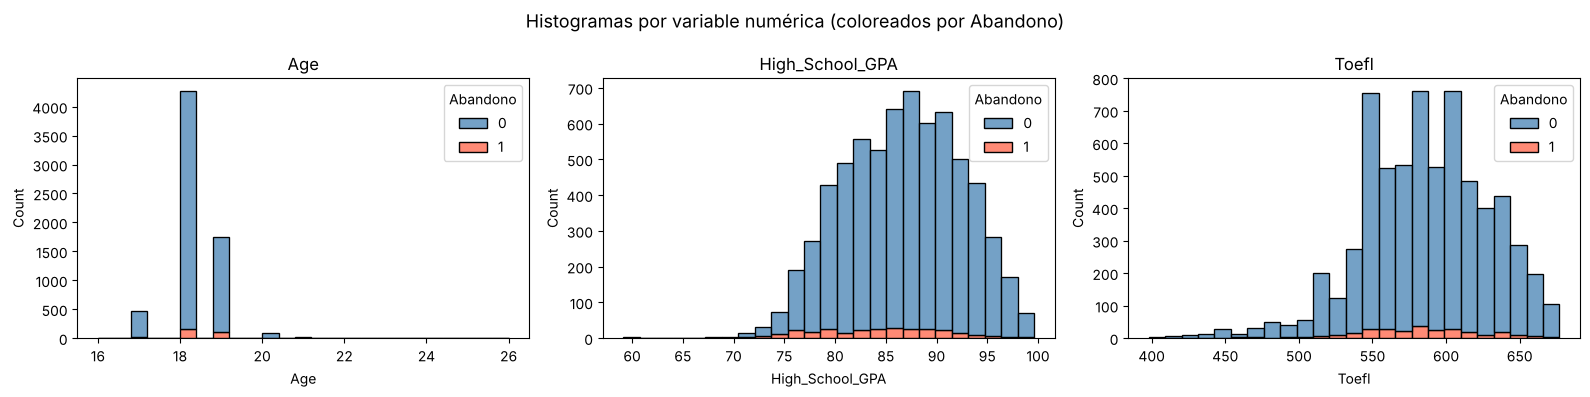

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle("Histogramas por variable numérica (coloreados por Abandono)", fontsize=13)

for ax, col in zip(axes, ['Age', 'High_School_GPA', 'Toefl']):
    sns.histplot(data=data, x=col, hue='Abandono', bins=25,
                 multiple='stack', palette=['steelblue', 'tomato'], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

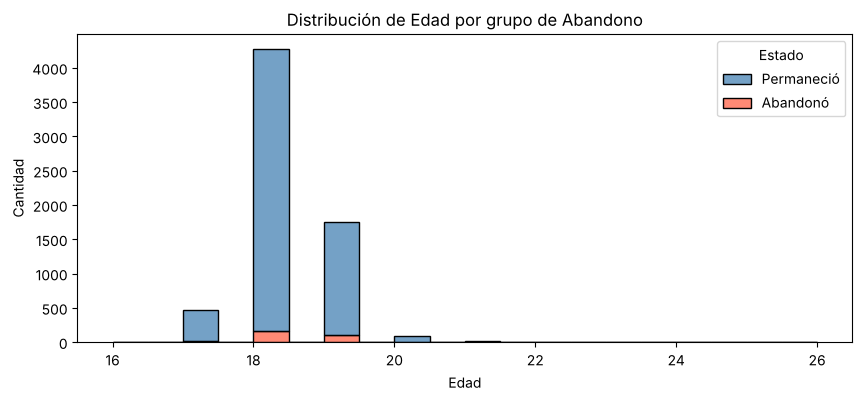

In [10]:
data['Estado'] = data['Abandono'].map({0: 'Permaneció', 1: 'Abandonó'})

plt.figure(figsize=(10, 4))
plt.title("Distribución de Edad por grupo de Abandono")
sns.histplot(data=data, x='Age', bins=20, hue='Estado',
             multiple='stack', palette=['steelblue', 'tomato'])
plt.xlabel("Edad")
plt.ylabel("Cantidad")
plt.show()

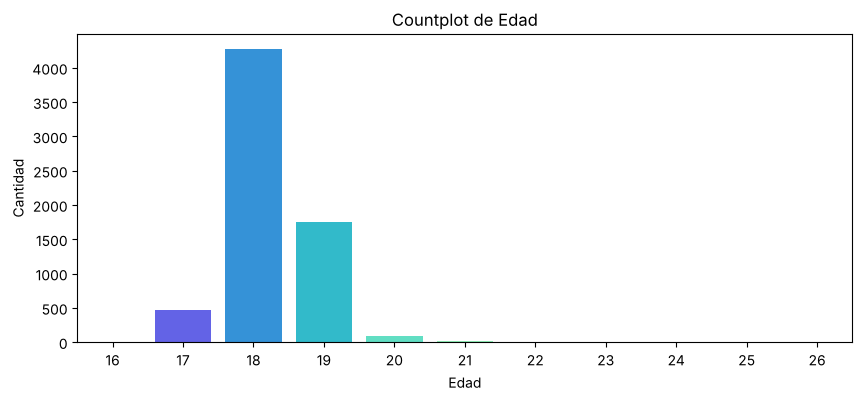

In [11]:
plt.figure(figsize=(10, 4))
plt.title("Countplot de Edad")
sns.countplot(x='Age', data=data, hue='Age', palette='rainbow', legend=False)
plt.xlabel("Edad")
plt.ylabel("Cantidad")
plt.show()

### 2.4 Abandono según Género

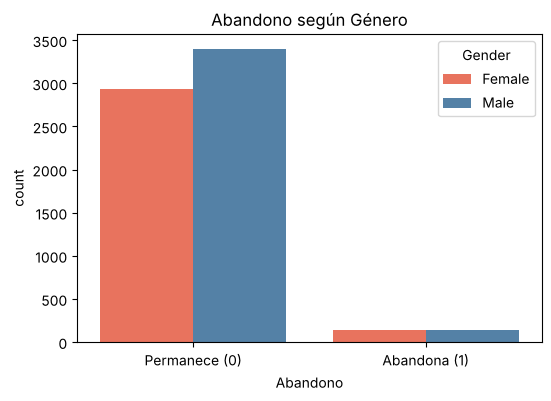

In [12]:
plt.figure(figsize=(6, 4))
plt.title("Abandono según Género")
sns.countplot(x='Abandono', data=data, hue='Gender', palette=['tomato', 'steelblue'])
plt.xticks([0, 1], ['Permanece (0)', 'Abandona (1)'])
plt.legend(title='Gender', labels=['Female', 'Male'])
plt.show()

### 2.5 Abandono según Nivel de Inglés

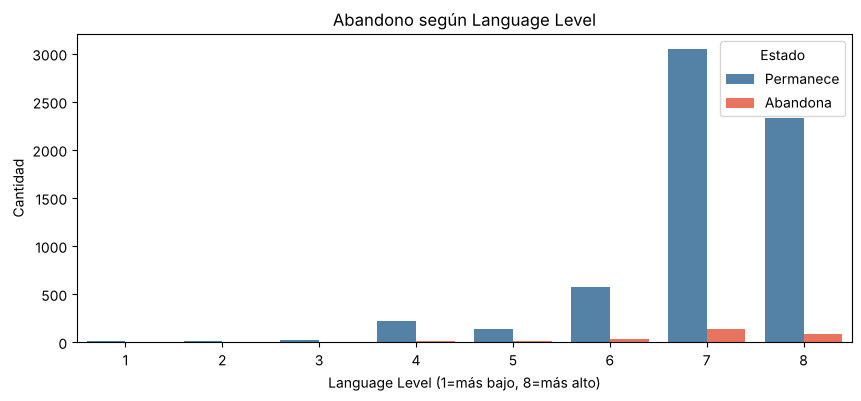

In [13]:
plt.figure(figsize=(10, 4))
plt.title("Abandono según Language Level")
ax = sns.countplot(x='Language_Level', data=data, hue='Abandono', palette=['steelblue', 'tomato'])
legend = ax.get_legend()
if legend:
    legend.set_title('Estado')
    legend.texts[0].set_text('Permanece')
    legend.texts[1].set_text('Abandona')
plt.xlabel("Language Level (1=más bajo, 8=más alto)")
plt.ylabel("Cantidad")
plt.show()

In [14]:
print("Tasa de abandono por Language_Level:")
print(data.groupby('Language_Level')['Abandono'].mean().round(3))

Tasa de abandono por Language_Level:
Language_Level
1    0.000
2    0.000
3    0.105
4    0.061
5    0.063
6    0.061
7    0.044
8    0.036
Name: Abandono, dtype: float64


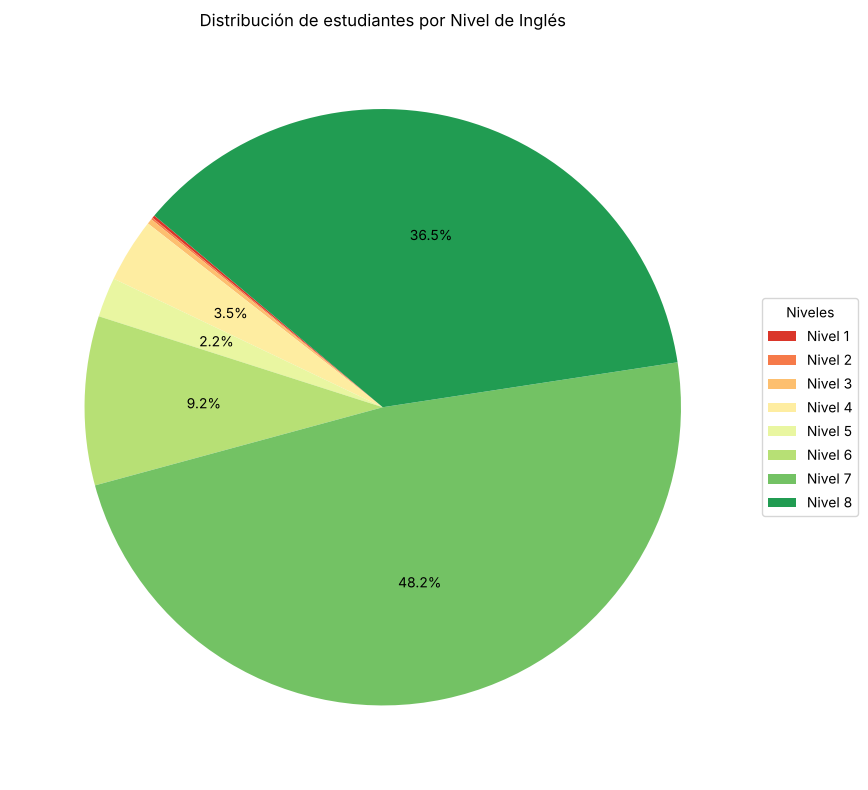

In [15]:
conteos = data['Language_Level'].value_counts().sort_index()

def porcentaje_visible(pct):
    return f'{pct:.1f}%' if pct >= 2 else ''

plt.figure(figsize=(10, 8))
wedges, texts, autotexts = plt.pie(
    conteos, autopct=porcentaje_visible, startangle=140,
    colors=sns.color_palette('RdYlGn', len(conteos))
)
plt.legend(wedges, [f'Nivel {i}' for i in conteos.index],
           title="Niveles", loc="center left", bbox_to_anchor=(1, 0.5))
plt.title("Distribución de estudiantes por Nivel de Inglés")
plt.tight_layout()
plt.show()

### 2.6 Promedios de cada variable según Abandono

In [16]:
data.groupby('Abandono')[['Gender','Age','High_School_GPA','Language_Level','Toefl']].mean().round(3)

,Gender,Age,High_School_GPA,Language_Level,Toefl
Abandono,,,,,
0,0.537,18.229,86.744,7.107,586.297
1,0.503,18.535,84.120,6.938,578.545


> **Hallazgos:** quienes abandonan tienen en promedio **menor GPA de preparatoria** (84.1 vs 86.7) y **mayor edad** al ingresar (18.5 vs 18.2). El TOEFL y el nivel de inglés son ligeramente menores en ese grupo.

### 2.7 Boxplots — comparación por grupo

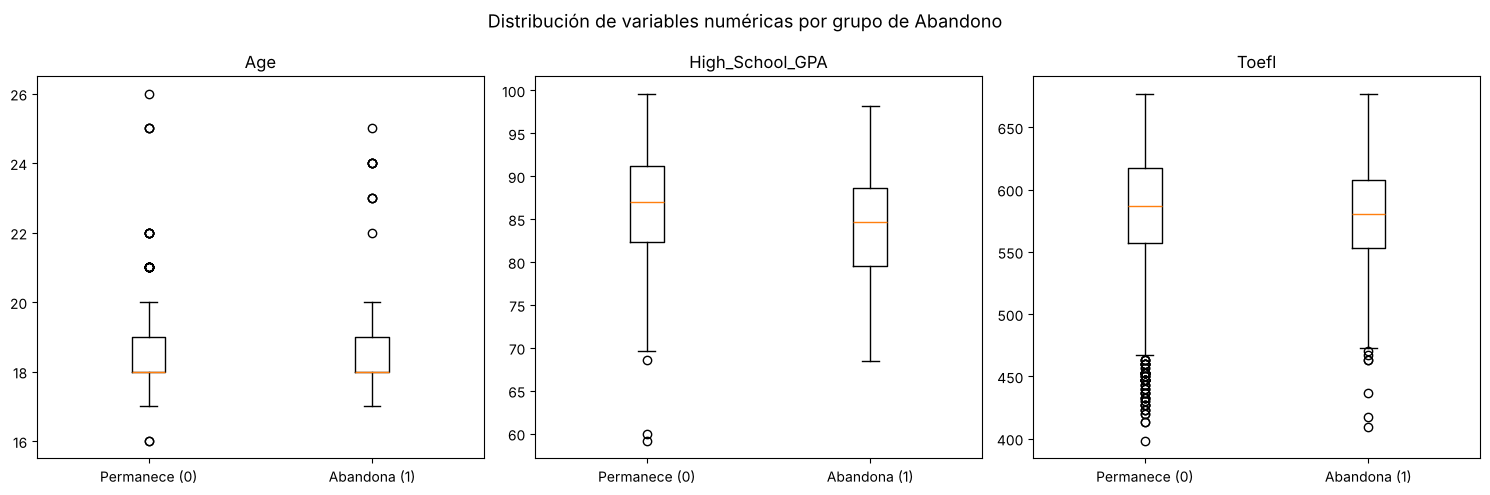

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Distribución de variables numéricas por grupo de Abandono", fontsize=13)
for ax, col in zip(axes, ['Age', 'High_School_GPA', 'Toefl']):
    ax.boxplot([data.loc[data['Abandono'] == 0, col],
                data.loc[data['Abandono'] == 1, col]],
               tick_labels=['Permanece (0)', 'Abandona (1)'])
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 2.8 Matriz de correlación

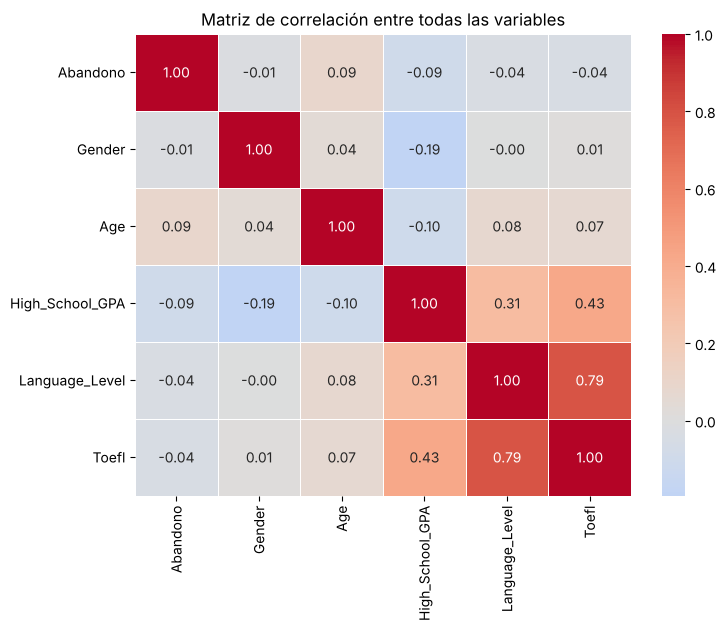

In [18]:
plt.figure(figsize=(8, 6))
plt.title("Matriz de correlación entre todas las variables")
sns.heatmap(data[['Abandono','Gender','Age','High_School_GPA','Language_Level','Toefl']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.show()

> **Hallazgo clave:** `Language_Level` y `Toefl` tienen una correlación de **0.79**. Es un caso de multicolinealidad: ambas miden esencialmente el dominio del inglés, así que no conviene incluir las dos.

## Paso 3 — Selección del modelo y de las variables

### 3.1 Modelo seleccionado
El modelo que evalúo con las técnicas de remuestreo es la **regresión logística binaria**, el mismo que construí en la actividad anterior. Lo elijo porque la variable objetivo es binaria (abandona / permanece), es un modelo **interpretable** —sus coeficientes se leen como Odds Ratio— y entrega probabilidades, lo que me permite ajustar el umbral de decisión según el costo de cada error. Esa interpretabilidad y su rapidez lo hacen idóneo para repetir el entrenamiento muchas veces, como exigen la validación cruzada y el bootstrapping.

### 3.2 ¿Por qué no incluyo `Language_Level`?
Dado que `Language_Level` y `Toefl` están muy correlacionadas (r = 0.79), verifico numéricamente que excluir una de ellas prácticamente no afecta el AUC.

In [19]:
from sklearn.pipeline import Pipeline

def auc_con_variables(cols):
    X = data[cols]
    y = data['Abandono']
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
    pipe = Pipeline([('sc', StandardScaler()), ('lr', LogisticRegression(max_iter=500))])
    pipe.fit(Xtr, ytr)
    return round(roc_auc_score(yte, pipe.predict_proba(Xte)[:, 1]), 4)

print("AUC con Language_Level y Toefl:", auc_con_variables(['Gender','Age','High_School_GPA','Language_Level','Toefl']))
print("AUC sin Language_Level         :", auc_con_variables(['Gender','Age','High_School_GPA','Toefl']))

AUC con Language_Level y Toefl: 0.6427
AUC sin Language_Level         : 0.6483


> La diferencia es mínima. Me quedo con el modelo más simple e interpretable y conservo `Toefl` por ser una escala más fina.

### 3.3 Separar variables predictoras (X) y objetivo (y)

In [20]:
feature_cols = ['Gender', 'Age', 'High_School_GPA', 'Toefl']
target_col   = 'Abandono'

X = data[feature_cols].copy()
y = data[target_col].astype(int).copy()

print("Variables predictoras (X):", list(X.columns))
print("Variable objetivo      (y):", target_col)
print("Shape X:", X.shape, "| Shape y:", y.shape)

Variables predictoras (X): ['Gender', 'Age', 'High_School_GPA', 'Toefl']
Variable objetivo      (y): Abandono
Shape X: (6620, 4) | Shape y: (6620,)


## Paso 4 — Preparación para el modelado

### 4.1 Dividir en entrenamiento y prueba

In [21]:
# stratify=y mantiene la misma proporción de abandono (~4.4%) en ambos conjuntos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=0, stratify=y
)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Tasa abandono -> train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

X_train: (4634, 4) | X_test: (1986, 4)
Tasa abandono -> train: 0.044 | test: 0.043


### 4.2 Escalar variables: estandarizar, normalizar o no escalar

Las variables están en escalas muy distintas (`Age` 16–26, `GPA` 59–99, `Toefl` 398–677). Comparo tres opciones de forma justa (mismo split y modelo), evaluando cada una en su umbral de mínimo costo, que es como realmente se usa el modelo.

In [22]:
def comparar_escalador(scaler):
    if scaler is None:
        Xtr, Xte = X_train.values, X_test.values
    else:
        sc = scaler.fit(X_train)             # se ajusta SOLO con train (sin fuga de datos)
        Xtr, Xte = sc.transform(X_train), sc.transform(X_test)
    lr = LogisticRegression(max_iter=500, solver='lbfgs').fit(Xtr, y_train)
    score = lr.predict_proba(Xte)[:, 1]
    auc = roc_auc_score(y_test, score)
    mejor = None
    for th in np.linspace(0.01, 0.99, 199):
        yp = (score >= th).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
        costo = 10_000 * fp + 80_000 * fn
        if mejor is None or costo < mejor['Costo mínimo']:
            mejor = {'Umbral óptimo': round(th, 3), 'Costo mínimo': costo, 'TP': tp}
    return round(auc, 4), mejor

resultados = []
for nombre, sc in [('Sin escalar', None),
                   ('StandardScaler (estandarización)', StandardScaler()),
                   ('MinMaxScaler (normalización)', MinMaxScaler())]:
    auc, mejor = comparar_escalador(sc)
    resultados.append({'Opción': nombre, 'AUC': auc, **mejor})

comp_scalers = pd.DataFrame(resultados)
comp_scalers

,Opción,AUC,Umbral óptimo,Costo mínimo,TP
0,Sin escalar,0.6484,0.089,6470000,15
1,StandardScaler (estandarización),0.6483,0.089,6460000,15
2,MinMaxScaler (normalización),0.6499,0.074,6440000,18


> En una regresión logística **escalar casi no cambia el resultado**: sin escalar y con `StandardScaler` se obtiene prácticamente el mismo AUC y el mismo costo mínimo; la normalización queda un poco por detrás. Elijo **`StandardScaler`** por interpretabilidad —deja los coeficientes en la misma escala para compararlos— y porque es la opción recomendada para modelos lineales.

### 4.3 Escalar con StandardScaler

In [23]:
scaler = StandardScaler()
scaler.fit(X_train)                       # aprende media y desv. estándar SOLO del train

X_train_scaled = scaler.transform(X_train)
X_test_scaled  = scaler.transform(X_test)

pd.DataFrame(X_train_scaled, columns=feature_cols).head()

,Gender,Age,High_School_GPA,Toefl
0,-1.073939,-0.364534,-0.518219,-0.609102
1,0.931151,-0.364534,0.265602,1.399736
2,0.931151,-0.364534,-0.062875,-0.770733
3,-1.073939,1.141038,-1.782068,-1.070904
4,-1.073939,-1.870107,0.500351,-0.147300


## Paso 5 — Construcción del modelo

### 5.1 Entrenar la Regresión Logística

In [24]:
logmodel = LogisticRegression(max_iter=500, solver='lbfgs')
logmodel.fit(X_train_scaled, y_train)
print(logmodel)

LogisticRegression(max_iter=500)


### 5.2 Coeficientes e interpretación (Odds Ratio)

Cada coeficiente β indica cómo cambia el log-odds de abandono: β > 0 lo aumenta y β < 0 lo disminuye. El **Odds Ratio = e^β** dice por cuánto se multiplican los odds de abandono.

In [25]:
coef_df = pd.DataFrame({
    'Variable'          : feature_cols,
    'Coeficiente β'     : logmodel.coef_[0],
    'Odds Ratio (1 DE)' : np.exp(logmodel.coef_[0])
}).sort_values('Coeficiente β')

print(f"Intercepto (β0): {logmodel.intercept_[0]:.3f}")
coef_df.round(3)

Intercepto (β0): -3.244


,Variable,Coeficiente β,Odds Ratio (1 DE)
2,High_School_GPA,-0.446,0.640
0,Gender,-0.210,0.810
3,Toefl,0.023,1.023
1,Age,0.316,1.372


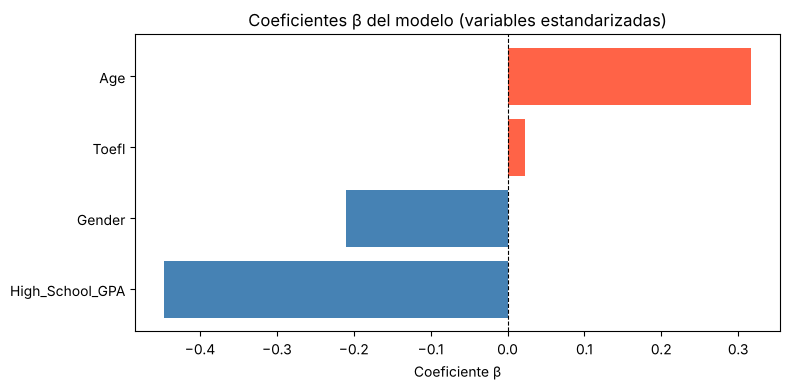

In [26]:
plt.figure(figsize=(8, 4))
plt.title("Coeficientes β del modelo (variables estandarizadas)")
colors = ['tomato' if c > 0 else 'steelblue' for c in coef_df['Coeficiente β']]
plt.barh(coef_df['Variable'], coef_df['Coeficiente β'], color=colors)
plt.axvline(0, linestyle='--', color='black', linewidth=0.8)
plt.xlabel("Coeficiente β")
plt.tight_layout()
plt.show()

> `High_School_GPA` es el predictor protector más fuerte y `Age` el principal factor de riesgo: a mayor edad de ingreso, mayores odds de abandono. `Gender` y `Toefl` tienen efectos protectores más pequeños.

## Paso 6 — Evaluación del desempeño (umbral 0.5)

In [27]:
y_scores = logmodel.predict_proba(X_test_scaled)[:, 1]
predicciones = logmodel.predict(X_test_scaled)

### 6.1 Reporte de clasificación y exactitud

In [28]:
print(classification_report(y_test, predicciones, target_names=['Permanece (0)', 'Abandona (1)']))
print("Accuracy:", round(accuracy_score(y_test, predicciones), 4))

               precision    recall  f1-score   support

Permanece (0)       0.96      1.00      0.98      1900
 Abandona (1)       0.00      0.00      0.00        86

     accuracy                           0.96      1986
    macro avg       0.48      0.50      0.49      1986
 weighted avg       0.92      0.96      0.94      1986

Accuracy: 0.9562


> **Paradoja de la exactitud:** la exactitud es ≈95.6 %, pero con el umbral 0.5 el modelo apenas detecta abandonos. Como la clase está desbalanceada, esta exactitud es engañosa: hay que ajustar el umbral y guiarse por el AUC y el costo.

### 6.2 Matriz de confusión (umbral 0.5)

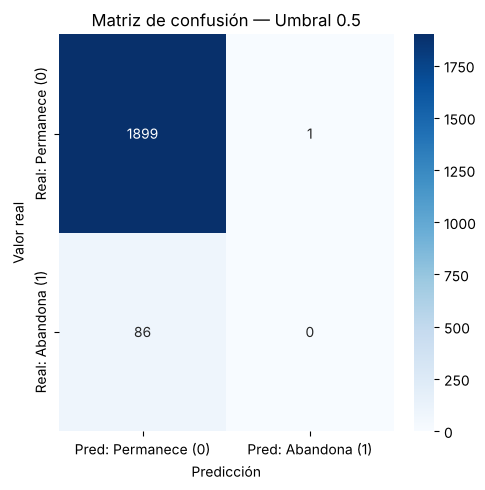

In [29]:
cm = confusion_matrix(y_test, predicciones)
plt.figure(figsize=(5, 5))
plt.title("Matriz de confusión — Umbral 0.5")
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            yticklabels=['Real: Permanece (0)', 'Real: Abandona (1)'],
            xticklabels=['Pred: Permanece (0)', 'Pred: Abandona (1)'])
plt.ylabel("Valor real")
plt.xlabel("Predicción")
plt.tight_layout()
plt.show()

### 6.3 Curva ROC

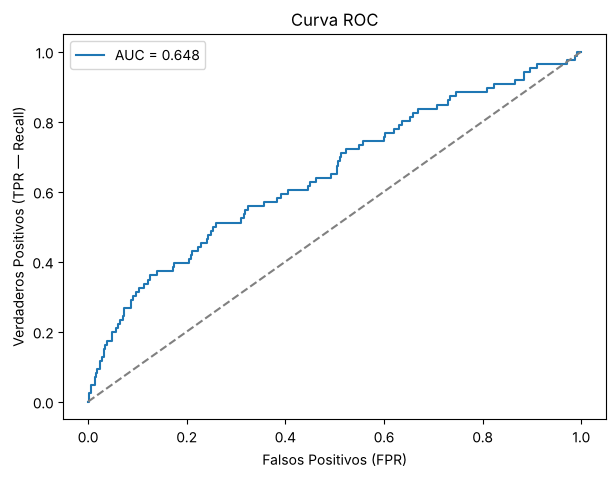

In [30]:
fpr, tpr, roc_thresholds = roc_curve(y_test, y_scores)
roc_auc = roc_auc_score(y_test, y_scores)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("Falsos Positivos (FPR)")
plt.ylabel("Verdaderos Positivos (TPR — Recall)")
plt.title("Curva ROC")
plt.legend()
plt.show()

> **AUC ≈ 0.64:** discriminación moderada, mejor que el azar pero lejos de ser perfecta. Con solo cuatro variables el modelo no captura factores como la situación económica o la asistencia, así que los patrones se deben tomar como hipótesis.

### 6.4 Curva Precisión-Recall

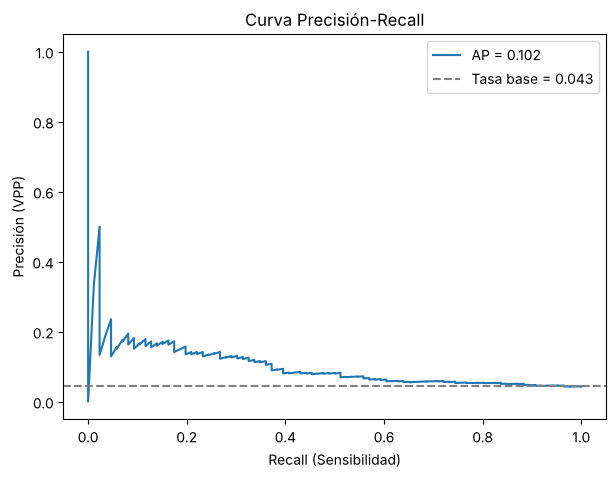

El modelo es 2.3x mejor que el azar (AP=0.102 vs tasa base=0.043)


In [31]:
ap = average_precision_score(y_test, y_scores)
precision_c, recall_c, pr_thresholds = precision_recall_curve(y_test, y_scores)

plt.figure(figsize=(7, 5))
plt.plot(recall_c, precision_c, label=f'AP = {ap:.3f}')
plt.axhline(y_test.mean(), linestyle='--', color='gray', label=f'Tasa base = {y_test.mean():.3f}')
plt.xlabel("Recall (Sensibilidad)")
plt.ylabel("Precisión (VPP)")
plt.title("Curva Precisión-Recall")
plt.legend()
plt.show()

print(f"El modelo es {ap/y_test.mean():.1f}x mejor que el azar (AP={ap:.3f} vs tasa base={y_test.mean():.3f})")

### 6.5 Precisión y Recall vs Umbral

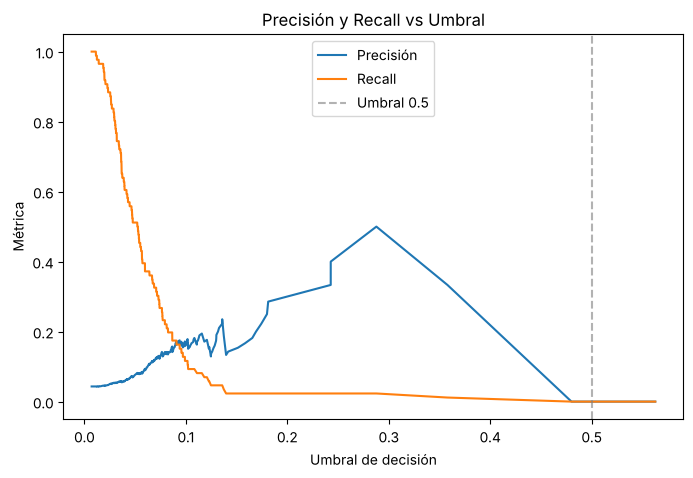

In [32]:
plt.figure(figsize=(8, 5))
plt.plot(pr_thresholds, precision_c[:-1], label='Precisión')
plt.plot(pr_thresholds, recall_c[:-1], label='Recall')
plt.axvline(0.5, linestyle='--', color='gray', alpha=0.6, label='Umbral 0.5')
plt.xlabel("Umbral de decisión")
plt.ylabel("Métrica")
plt.title("Precisión y Recall vs Umbral")
plt.legend()
plt.show()

> Con umbral 0.5 el Recall cae casi a cero: el modelo no clasifica a casi nadie como "abandona". Esto confirma que 0.5 no es el umbral adecuado para este problema.

## Paso 7 — Selección del umbral óptimo por costos

El umbral no debe maximizar la exactitud, sino minimizar el costo total:
`Costo Total = C_FP × FP + C_FN × FN = $10,000 × FP + $80,000 × FN`

In [33]:
C_FP = 10_000   # costo de un Falso Positivo
C_FN = 80_000   # costo de un Falso Negativo

def evaluar_umbral(y_true, y_score, th):
    y_pred = (y_score >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        'Umbral'   : round(th, 3),
        'TP'       : tp, 'FP': fp, 'TN': tn, 'FN': fn,
        'Precisión': round(precision_score(y_true, y_pred, zero_division=0), 3),
        'Recall'   : round(recall_score(y_true, y_pred, zero_division=0), 3),
        'F1'       : round(f1_score(y_true, y_pred, zero_division=0), 3),
        'Costo Total': C_FP * fp + C_FN * fn
    }

### 7.1 Comparación de umbrales de referencia

In [34]:
umbrales_demo = [0.05, 0.10, 0.30, 0.50, 0.70]
pd.DataFrame([evaluar_umbral(y_test, y_scores, th) for th in umbrales_demo])

,Umbral,TP,FP,TN,FN,Precisión,Recall,F1,Costo Total
0,0.05,44,529,1371,42,0.077,0.512,0.134,8650000
1,0.10,10,52,1848,76,0.161,0.116,0.135,6600000
2,0.30,1,2,1898,85,0.333,0.012,0.022,6820000
3,0.50,0,1,1899,86,0.000,0.000,0.000,6890000
4,0.70,0,0,1900,86,0.000,0.000,0.000,6880000


> Con umbral 0.50 la exactitud es alta pero detecta casi ningún abandono; con 0.05 detecta muchos más pero genera demasiadas intervenciones innecesarias. El balance lo define el costo.

### 7.2 Umbral óptimo (mínimo costo)

In [35]:
umbrales = np.linspace(0.01, 0.99, 199)
costos_df = pd.DataFrame([evaluar_umbral(y_test, y_scores, th) for th in umbrales])

best_idx         = costos_df['Costo Total'].idxmin()
umbral_min_costo = float(costos_df.loc[best_idx, 'Umbral'])
costo_minimo     = float(costos_df.loc[best_idx, 'Costo Total'])

print(f"Umbral teórico        = {C_FP / (C_FP + C_FN):.3f}")
print(f"Umbral óptimo hallado = {umbral_min_costo:.3f}")
print(f"Costo total mínimo    = ${costo_minimo:,.0f}")

Umbral teórico        = 0.111
Umbral óptimo hallado = 0.089
Costo total mínimo    = $6,460,000


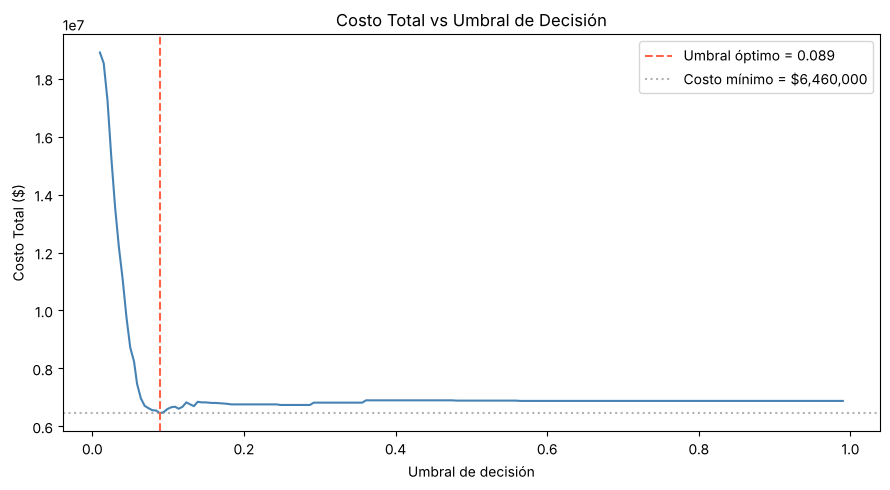

In [36]:
plt.figure(figsize=(9, 5))
plt.plot(costos_df['Umbral'], costos_df['Costo Total'], color='steelblue')
plt.axvline(umbral_min_costo, linestyle='--', color='tomato', label=f'Umbral óptimo = {umbral_min_costo:.3f}')
plt.axhline(costo_minimo, linestyle=':', color='gray', alpha=0.6, label=f'Costo mínimo = ${costo_minimo:,.0f}')
plt.xlabel("Umbral de decisión")
plt.ylabel("Costo Total ($)")
plt.title("Costo Total vs Umbral de Decisión")
plt.legend()
plt.tight_layout()
plt.show()

### 7.3 Matriz de confusión con el umbral óptimo

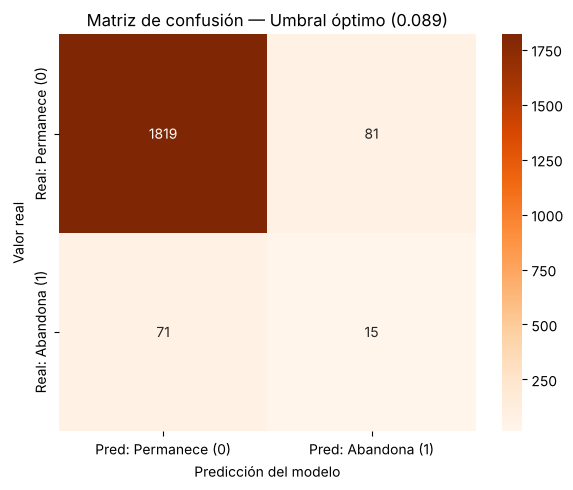

TP (detectados a tiempo)        : 15
FP (intervenciones innecesarias): 81
FN (abandonos no detectados)    : 71
Estudiantes marcados como riesgo: 96 (4.8% del total de prueba)


In [37]:
y_pred_opt = (y_scores >= umbral_min_costo).astype(int)
cm_opt = confusion_matrix(y_test, y_pred_opt)

plt.figure(figsize=(6, 5))
plt.title(f"Matriz de confusión — Umbral óptimo ({umbral_min_costo:.3f})")
sns.heatmap(cm_opt, annot=True, fmt='d', cmap='Oranges',
            yticklabels=['Real: Permanece (0)', 'Real: Abandona (1)'],
            xticklabels=['Pred: Permanece (0)', 'Pred: Abandona (1)'])
plt.ylabel("Valor real")
plt.xlabel("Predicción del modelo")
plt.tight_layout()
plt.show()

tn_o, fp_o, fn_o, tp_o = cm_opt.ravel()
print(f"TP (detectados a tiempo)        : {tp_o}")
print(f"FP (intervenciones innecesarias): {fp_o}")
print(f"FN (abandonos no detectados)    : {fn_o}")
print(f"Estudiantes marcados como riesgo: {tp_o + fp_o} ({(tp_o+fp_o)/len(y_test)*100:.1f}% del total de prueba)")

> Con el umbral óptimo el modelo pasa de detectar casi ningún abandono (umbral 0.5) a identificar un grupo de riesgo manejable. Este modelo —con sus variables, su escalado y su umbral— es el que someto a las técnicas de remuestreo en los pasos siguientes.

## Paso 8 — Implementación de la validación cruzada (k-fold)

La validación cruzada estima qué tan bien generaliza el modelo a datos no vistos. Uso **k-fold estratificada** (`k = 5`) porque la clase positiva es escasa y la estratificación mantiene la proporción de abandono en cada pliegue. La **repito 10 veces** con particiones distintas para estimar también la variabilidad del desempeño. El escalado va dentro de un `Pipeline` para ajustarse solo con el pliegue de entrenamiento y evitar fuga de información. Reporto, para cada métrica, la **media** y la **varianza** entre pliegues.

In [38]:
def pipeline_logistico():
    return Pipeline([('sc', StandardScaler()),
                     ('lr', LogisticRegression(max_iter=500, solver='lbfgs'))])

def metricas(y_true, proba, umbral=0.5):
    pred = (proba >= umbral).astype(int)
    return {
        'AUC'      : roc_auc_score(y_true, proba),
        'Exactitud': accuracy_score(y_true, pred),
        'Recall'   : recall_score(y_true, pred, zero_division=0),
        'Precisión': precision_score(y_true, pred, zero_division=0),
        'F1'       : f1_score(y_true, pred, zero_division=0),
        'Brier'    : brier_score_loss(y_true, proba)   # error cuadrático medio de las probabilidades
    }

metricas_cols = ['AUC', 'Exactitud', 'Recall', 'Precisión', 'F1', 'Brier']

In [39]:
K = 5
REPETICIONES = 10
cv = RepeatedStratifiedKFold(n_splits=K, n_repeats=REPETICIONES, random_state=42)

filas_cv, curvas_roc = [], []
for idx_tr, idx_te in cv.split(X, y):
    modelo = pipeline_logistico().fit(X.iloc[idx_tr], y.iloc[idx_tr])
    proba = modelo.predict_proba(X.iloc[idx_te])[:, 1]
    filas_cv.append(metricas(y.iloc[idx_te], proba))
    fpr_f, tpr_f, _ = roc_curve(y.iloc[idx_te], proba)
    curvas_roc.append((fpr_f, tpr_f))

res_cv = pd.DataFrame(filas_cv)
print(f"Validación cruzada: {K}-fold x {REPETICIONES} repeticiones = {len(res_cv)} iteraciones\n")

resumen_cv = pd.DataFrame({
    'Media'   : res_cv[metricas_cols].mean(),
    'Varianza': res_cv[metricas_cols].var(ddof=1),
    'Desv.Est': res_cv[metricas_cols].std(ddof=1),
    'Mínimo'  : res_cv[metricas_cols].min(),
    'Máximo'  : res_cv[metricas_cols].max()
})
resumen_cv.round(4)

Validación cruzada: 5-fold x 10 repeticiones = 50 iteraciones



,Media,Varianza,Desv.Est,Mínimo,Máximo
AUC,0.6480,0.0016,0.0404,0.5683,0.7234
Exactitud,0.9564,0.0000,0.0008,0.9547,0.9585
Recall,0.0052,0.0001,0.0088,0.0000,0.0351
Precisión,0.2467,0.1749,0.4182,0.0000,1.0000
F1,0.0102,0.0003,0.0171,0.0000,0.0678
Brier,0.0408,0.0000,0.0006,0.0396,0.0423


### 8.1 Variabilidad del desempeño entre pliegues

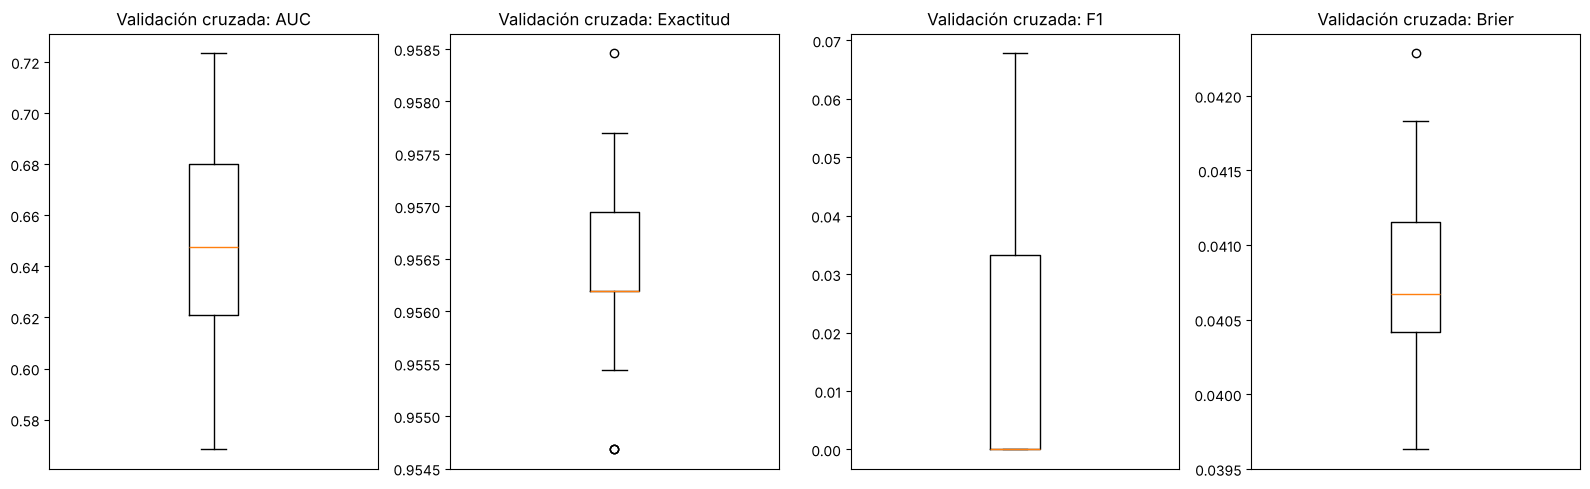

In [40]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, met in zip(axes, ['AUC', 'Exactitud', 'F1', 'Brier']):
    ax.boxplot(res_cv[met])
    ax.set_title(f"Validación cruzada: {met}")
    ax.set_xticks([])
plt.tight_layout()
plt.show()

### 8.2 Curva ROC promedio de la validación cruzada

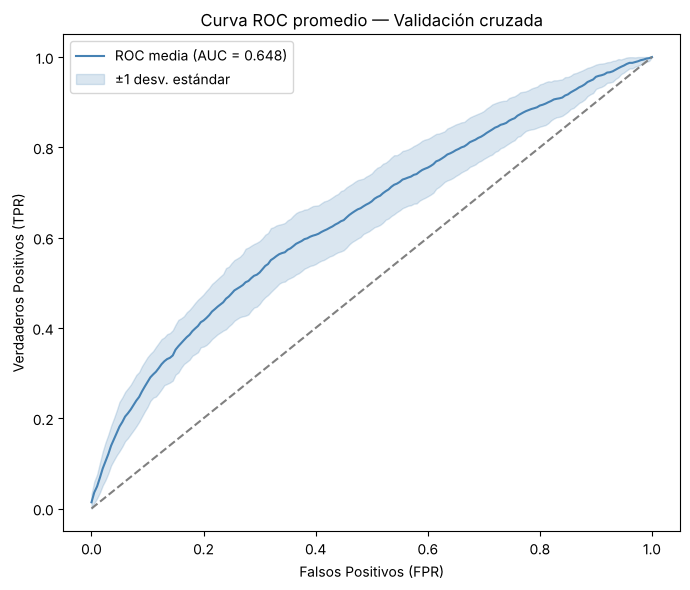

In [41]:
grilla = np.linspace(0, 1, 201)
tprs = np.array([np.interp(grilla, f, t) for f, t in curvas_roc])
media_tpr = tprs.mean(axis=0)
desv_tpr  = tprs.std(axis=0, ddof=1)

plt.figure(figsize=(7, 6))
plt.plot(grilla, media_tpr, color='steelblue', label=f"ROC media (AUC = {res_cv['AUC'].mean():.3f})")
plt.fill_between(grilla, np.clip(media_tpr - desv_tpr, 0, 1), np.clip(media_tpr + desv_tpr, 0, 1),
                 alpha=0.2, color='steelblue', label='±1 desv. estándar')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("Falsos Positivos (FPR)")
plt.ylabel("Verdaderos Positivos (TPR)")
plt.title("Curva ROC promedio — Validación cruzada")
plt.legend()
plt.tight_layout()
plt.show()

> La media de AUC confirma lo visto en el conjunto de prueba, y la desviación estándar entre pliegues es pequeña: el desempeño del modelo es **estable**, no depende de una partición afortunada. El Recall y el F1 con umbral 0.5 son bajos, coherente con el desbalance ya analizado.

## Paso 9 — Implementación del bootstrapping (.632)

El bootstrapping estima la variabilidad del desempeño mediante **muestreo con reemplazo**. En cada una de las `B = 200` réplicas tomo una muestra del mismo tamaño que el conjunto original (con reemplazo), entreno el modelo en ella y lo evalúo en las observaciones que quedaron fuera (**OOB**, *out-of-bag*). Combino ambos desempeños con el **estimador .632**:

`.632 = 0.368 × desempeño_aparente + 0.632 × desempeño_OOB`

que corrige el optimismo de evaluar sobre los mismos datos de entrenamiento.

In [42]:
B = 200
rng = np.random.RandomState(42)
n = len(X)
indices = np.arange(n)

filas_boot = []
for b in range(B):
    idx_boot = rng.choice(indices, size=n, replace=True)
    idx_oob  = np.setdiff1d(indices, idx_boot)

    modelo = pipeline_logistico().fit(X.iloc[idx_boot], y.iloc[idx_boot])
    aparente = metricas(y.iloc[idx_boot], modelo.predict_proba(X.iloc[idx_boot])[:, 1])
    oob      = metricas(y.iloc[idx_oob],  modelo.predict_proba(X.iloc[idx_oob])[:, 1])

    filas_boot.append({m: 0.368 * aparente[m] + 0.632 * oob[m] for m in metricas_cols})

res_boot = pd.DataFrame(filas_boot)
print(f"Bootstrapping .632: {B} réplicas\n")

resumen_boot = pd.DataFrame({
    'Media'   : res_boot[metricas_cols].mean(),
    'Varianza': res_boot[metricas_cols].var(ddof=1),
    'Desv.Est': res_boot[metricas_cols].std(ddof=1),
    'IC 2.5%' : res_boot[metricas_cols].quantile(0.025),
    'IC 97.5%': res_boot[metricas_cols].quantile(0.975)
})
resumen_boot.round(4)

Bootstrapping .632: 200 réplicas



,Media,Varianza,Desv.Est,IC 2.5%,IC 97.5%
AUC,0.6497,0.0001,0.0105,0.6283,0.6684
Exactitud,0.9563,0.0000,0.0015,0.9536,0.9592
Recall,0.0056,0.0000,0.0037,0.0011,0.0127
Precisión,0.3824,0.0363,0.1905,0.0598,0.7547
F1,0.0110,0.0001,0.0072,0.0021,0.0244
Brier,0.0408,0.0000,0.0013,0.0383,0.0430


### 9.1 Distribución del desempeño (AUC y F1)

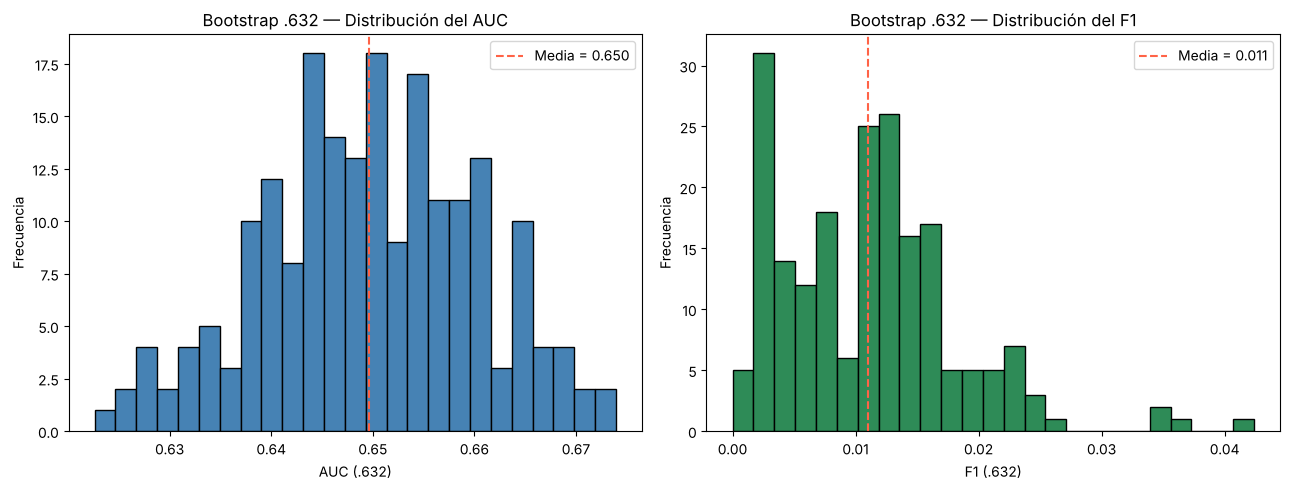

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(res_boot['AUC'], bins=25, color='steelblue', edgecolor='black')
axes[0].axvline(res_boot['AUC'].mean(), color='tomato', linestyle='--',
                label=f"Media = {res_boot['AUC'].mean():.3f}")
axes[0].set_title("Bootstrap .632 — Distribución del AUC")
axes[0].set_xlabel("AUC (.632)")
axes[0].set_ylabel("Frecuencia")
axes[0].legend()

axes[1].hist(res_boot['F1'], bins=25, color='seagreen', edgecolor='black')
axes[1].axvline(res_boot['F1'].mean(), color='tomato', linestyle='--',
                label=f"Media = {res_boot['F1'].mean():.3f}")
axes[1].set_title("Bootstrap .632 — Distribución del F1")
axes[1].set_xlabel("F1 (.632)")
axes[1].set_ylabel("Frecuencia")
axes[1].legend()
plt.tight_layout()
plt.show()

> El intervalo de percentiles 2.5 %–97.5 % del AUC es la estimación de incertidumbre que entrega el bootstrap: el desempeño del modelo se mueve dentro de un rango estrecho, lo que indica una estimación **robusta**.

## Paso 10 — Evaluación y comparación de resultados

Finalmente comparo lado a lado las estimaciones de ambas técnicas para analizar la estabilidad y la capacidad de generalización del modelo.

In [44]:
comparacion = pd.DataFrame({
    'CV — Media'        : res_cv[metricas_cols].mean(),
    'CV — Desv.Est'     : res_cv[metricas_cols].std(ddof=1),
    'Bootstrap — Media' : res_boot[metricas_cols].mean(),
    'Bootstrap — Desv.Est': res_boot[metricas_cols].std(ddof=1)
})
comparacion.round(4)

,CV — Media,CV — Desv.Est,Bootstrap — Media,Bootstrap — Desv.Est
AUC,0.6480,0.0404,0.6497,0.0105
Exactitud,0.9564,0.0008,0.9563,0.0015
Recall,0.0052,0.0088,0.0056,0.0037
Precisión,0.2467,0.4182,0.3824,0.1905
F1,0.0102,0.0171,0.0110,0.0072
Brier,0.0408,0.0006,0.0408,0.0013


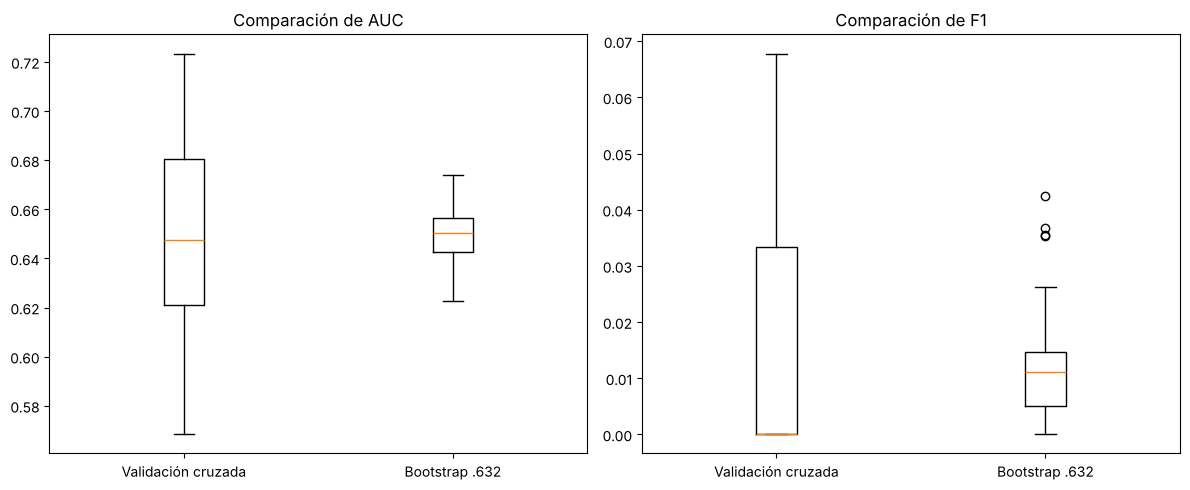

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, met in zip(axes, ['AUC', 'F1']):
    ax.boxplot([res_cv[met], res_boot[met]])
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['Validación cruzada', 'Bootstrap .632'])
    ax.set_title(f"Comparación de {met}")
plt.tight_layout()
plt.show()

> **Lectura de la comparación:**
> - Ambas técnicas coinciden en la **media de AUC**, lo que da confianza en que es una estimación fiable del desempeño real del modelo.
> - El **bootstrap muestra menor desviación estándar** que la validación cruzada: al usar réplicas del tamaño completo del dataset, sus estimaciones son más estables, mientras que cada pliegue de la CV entrena con menos datos y evalúa sobre pocos casos positivos.
> - La **validación cruzada** tiene la ventaja de ser una estimación casi insesgada y fácil de interpretar; el **bootstrap** aporta además una distribución completa e intervalos de confianza del desempeño.
> - En conjunto, las dos técnicas confirman que el modelo es **estable y generaliza de forma consistente**, aunque con una capacidad de discriminación **moderada** limitada por las variables disponibles, no por la cantidad de datos ni por la partición elegida.

## Paso 11 — EXTRA: Hold-Out como tercera técnica de validación

> **Nota:** esta sección es un **elemento extra** que no pide la rúbrica. La incluyo para completar las **tres técnicas de validación** que vimos en clase —Hold-Out, Validación Cruzada (K-Fold) y Bootstrapping— y así comparar las tres sobre el mismo modelo.

El **Hold-Out** es la técnica más simple: una única división en entrenamiento y prueba. Es rápida, pero su estimación depende por completo de esa partición, por lo que **no entrega una medida de variabilidad**. Aquí reutilizo el modelo ya entrenado en el Paso 5 y lo evalúo sobre el conjunto de prueba (umbral 0.5, igual que en las otras dos técnicas para que la comparación sea justa).

In [46]:
# Estimación Hold-Out: el modelo entrenado en el Paso 5, evaluado sobre el conjunto de prueba
holdout = metricas(y_test, y_scores)

tabla_tecnicas = pd.DataFrame({
    'Hold-Out'              : pd.Series(holdout),
    'Validación cruzada'    : res_cv[metricas_cols].mean(),
    'Bootstrap .632'        : res_boot[metricas_cols].mean()
}).loc[metricas_cols]
tabla_tecnicas.round(4)

,Hold-Out,Validación cruzada,Bootstrap .632
AUC,0.6483,0.6480,0.6497
Exactitud,0.9562,0.9564,0.9563
Recall,0.0000,0.0052,0.0056
Precisión,0.0000,0.2467,0.3824
F1,0.0000,0.0102,0.0110
Brier,0.0407,0.0408,0.0408


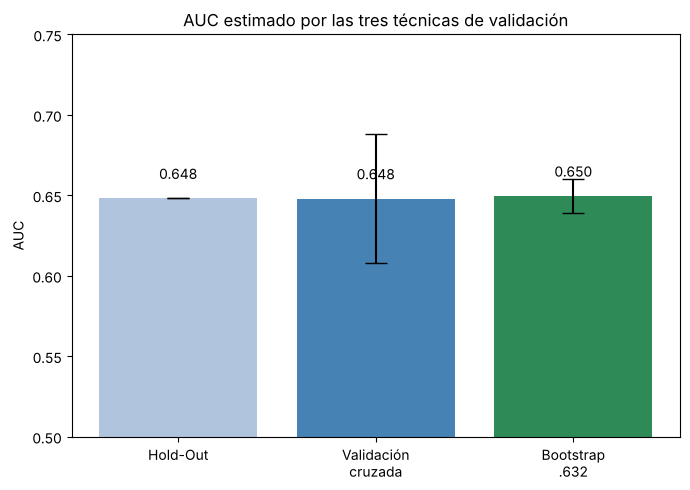

In [47]:
# Comparación del AUC entre las tres técnicas (barra de error = desv. estándar cuando aplica)
medias = [holdout['AUC'], res_cv['AUC'].mean(), res_boot['AUC'].mean()]
errores = [0, res_cv['AUC'].std(ddof=1), res_boot['AUC'].std(ddof=1)]
etiquetas = ['Hold-Out', 'Validación\ncruzada', 'Bootstrap\n.632']

plt.figure(figsize=(7, 5))
plt.bar(etiquetas, medias, yerr=errores, capsize=8,
        color=['lightsteelblue', 'steelblue', 'seagreen'])
plt.ylim(0.5, 0.75)
plt.ylabel("AUC")
plt.title("AUC estimado por las tres técnicas de validación")
for i, m in enumerate(medias):
    plt.text(i, m + 0.012, f"{m:.3f}", ha='center')
plt.tight_layout()
plt.show()

> **Lectura:** las tres técnicas coinciden en un AUC cercano a **0.65**, lo que refuerza que es una estimación fiable del desempeño real del modelo. La diferencia está en lo que cada una aporta:
> - **Hold-Out** da un solo número, rápido pero sin medida de incertidumbre y sensible a la partición elegida.
> - **Validación cruzada** promedia varias particiones y entrega la variabilidad entre pliegues.
> - **Bootstrap** genera una distribución completa con intervalos de confianza y la estimación más estable.
>
> Que las tres converjan al mismo valor es la mejor evidencia de que el modelo generaliza de forma consistente; el remuestreo (CV y bootstrap) añade sobre el hold-out la cuantificación de la incertidumbre que la decisión de negocio necesita.